# IMAGO | Air Temperature — Exploring Air Temperature Indicators Across the UK

**Data:** [IMAGO Air Temperature Indicators per MSOA](https://data.imago.ac.uk/datasets?search=air+temperature)

**Goal:** Explore the IMAGO air temperature product and understand the distribution and spatial patterns of two heat-related indicators using 2024 as an example.

> **Getting the data**
>
> The IMAGO air temperature data is hosted on our [data catalogue](https://data.imago.ac.uk/). To download it:
>
> 1. **Sign up** for a free account on the data catalogue and log in.
> 2. **Search** for `air temperature MSOA` (or browse the [temperature datasets](https://data.imago.ac.uk/datasets?search=air+temperature)).
> 3. Open your chosen yearly dataset and download the `.gpkg` file.
> 4. Save the file in `data/air_temperature/` in your project, keeping the original filename.
>
> Annual datasets are available for 2015–2024 in CSV and GeoPackage formats. Only the 2024 GeoPackage is required for this example. You can select another available year in the loading cell below.
> 
> <span style="color:#1565C0;"><strong>Note: If the data are already provided in your workspace, there is no need to download them again.</strong></span>

## What are Air Temperature Indicators?

The IMAGO product summarises HadUK-Grid air temperature data (1 km source grid) for MSOA-equivalent small areas across the UK. It includes annual and seasonal temperatures, extreme temperature events, variability and anomalies. The resulting indicators represent area-level estimates rather than individual grid-cell observations.

## The Reason for the Data

Air temperature indicators support research into geographical differences in thermal conditions and heat exposure. Providing these indicators at standard statistical geographies facilitates integration with population, housing, health and environmental datasets. Seasonal temperatures and the frequency of extreme hot days describe complementary aspects of heat. Air temperature is distinct from satellite-derived land surface temperature.

## Importing Libraries

In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


## Loading the Dataset

Each GeoPackage contains small-area boundaries and associated air temperature indicators. First, select a year, load the dataset and inspect its structure. The example uses 2024.

In [2]:
year = 2024
folders = [Path("../data/air_temperature"), Path("data/air_temperature"), Path("data")]

def load_temperature(year):
    for folder in folders:
        files = sorted(folder.glob(f"*MSOA*{year}*.gpkg"))
        if len(files) > 1:
            raise ValueError(f"Multiple files for {year} in {folder}; select the intended file.")
        if files:
            print("Loading:", files[0])
            return gpd.read_file(files[0])
    raise FileNotFoundError(f"No MSOA GeoPackage for {year}. Check the data folders.")

msoa_temp = load_temperature(year)
msoa_temp.head()

Loading: ../data/air_temperature/temperature_indicators_MSOA_2024_GeoPackage.gpkg


,dt_zn_c,dt_zn_n,annual_mean_tmp,annual_max_tmp,annual_min_tmp,winter_mean_tmp,spring_mean_tmp,summer_mean_tmp,autumn_mean_tmp,summer_max_tmp,winter_min_tmp,temporal_sd_tmp,tmp_anomaly_absolute,tmp_anomaly_relative,extreme_hot_days_mean,hot_spell_3day_mean,geometry
0,E02000001,City of London 001,12.763455,16.280210,9.247190,7.962327,12.237062,18.246445,12.783379,23.006287,5.307874,4.218369,2.558206,3.939247,3.0,7.00000,"MULTIPOLYGON (((532135.138 182198.131, 532158...."
1,E02000002,Barking and Dagenham 001,12.076904,15.995796,8.215314,7.301272,11.551524,17.542759,12.085314,22.753950,4.413336,4.201226,2.472255,4.046119,3.0,7.00000,"MULTIPOLYGON (((548881.563 190845.265, 548881...."
2,E02000003,Barking and Dagenham 002,12.203361,16.079384,8.376277,7.425026,11.671482,17.684784,12.206841,22.834980,4.557454,4.209268,2.478608,4.044049,3.0,7.00871,"MULTIPOLYGON (((549102.438 189324.625, 548954...."
3,E02000004,Barking and Dagenham 003,12.338967,16.196173,8.529167,7.562093,11.781488,17.846867,12.342216,22.967804,4.709777,4.221317,2.477158,4.074961,3.0,8.00000,"MULTIPOLYGON (((551550.056 187364.705, 551478 ..."
4,E02000005,Barking and Dagenham 004,12.341122,16.168375,8.552910,7.556808,11.802893,17.843620,12.337282,22.924101,4.712059,4.220945,2.483515,4.043092,3.0,7.67559,"MULTIPOLYGON (((549099.634 187656.076, 549161...."


## Exploring the Dataset

The principal variables used throughout this notebook are:

- `dt_zn_c`: Unique small-area identifier.
- `dt_zn_n`: Small-area name.
- `summer_max_tmp`: Summer maximum air temperature indicator (°C).
- `extreme_hot_days_mean`: Mean number of days crossing the product's extreme-heat threshold (days).
- `geometry`: Small-area boundary geometry.

These two temperature indicators capture different aspects of heat. Consult the product metadata for the exact temporal aggregation and extreme-heat threshold; the summer maximum indicator should not be interpreted as an absolute instantaneous peak.

Before proceeding, check the number of areas, coordinate reference system, available variables and missing values.

In [3]:
indicators = ["summer_max_tmp", "extreme_hot_days_mean"]
print("Number of areas:", len(msoa_temp))
print("CRS:", msoa_temp.crs)
print("Available columns:", msoa_temp.columns.tolist())
print("Missing values:")
msoa_temp[indicators].isna().sum()

Number of areas: 9448
CRS: EPSG:27700
Available columns: ['dt_zn_c', 'dt_zn_n', 'annual_mean_tmp', 'annual_max_tmp', 'annual_min_tmp', 'winter_mean_tmp', 'spring_mean_tmp', 'summer_mean_tmp', 'autumn_mean_tmp', 'summer_max_tmp', 'winter_min_tmp', 'temporal_sd_tmp', 'tmp_anomaly_absolute', 'tmp_anomaly_relative', 'extreme_hot_days_mean', 'hot_spell_3day_mean', 'geometry']
Missing values:


summer_max_tmp           0
extreme_hot_days_mean    0
dtype: int64

> **Note:** The 2024 dataset contains 9,448 MSOA-equivalent areas across the UK and uses the British National Grid (EPSG:27700). Neither selected indicator contains missing attribute values.

## Analysing the Dataset

### Summary Statistics

Calculate summary statistics to understand the range and variation of the two indicators. Each geographical area contributes equally.

In [4]:
msoa_temp[indicators].describe().round(2)

,summer_max_tmp,extreme_hot_days_mean
count,9448.00,9448.00
mean,20.23,0.67
std,1.80,1.11
min,13.65,0.00
25%,18.63,0.00
50%,20.46,0.00
75%,21.72,1.00
max,23.16,4.65


> **Note:** In 2024, the summer maximum temperature indicator ranges from 13.65°C to 23.16°C, with a mean of 20.23°C. The extreme hot days indicator averages 0.67 days and has a median of zero. These are unweighted statistics across small areas, not area-weighted or population-weighted national estimates.

### Distribution of the Indicators

Histograms show how frequently different indicator values occur across small areas.

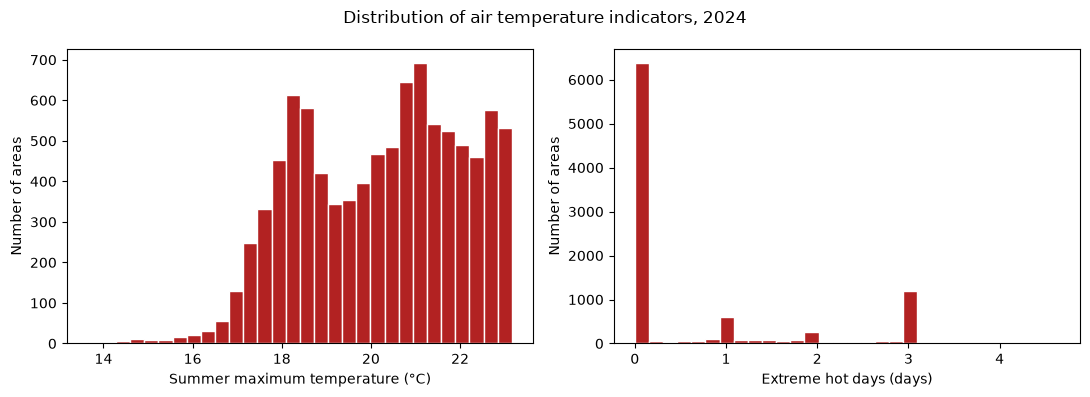

In [5]:
labels = ["Summer maximum temperature (°C)", "Extreme hot days (days)"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, label in zip(axes, indicators, labels):
    ax.hist(msoa_temp[col].dropna(), bins=30, color="firebrick", edgecolor="white")
    ax.set(xlabel=label, ylabel="Number of areas")
fig.suptitle(f"Distribution of air temperature indicators, {year}")
plt.tight_layout()
plt.show()

> **Note:** The distribution of summer maximum air temperature in 2024 shows prominent concentrations around 18–19°C and 21°C. The distribution of extreme hot days is strongly right-skewed, with most areas having values at or near zero and a smaller concentration around three days. The two indicators capture complementary aspects of heat: summer temperature conditions and the frequency of extreme heat events.

## Visualising the Dataset

Map the two indicators side by side to understand their geographical distribution. Each map has its own colour scale and unit.

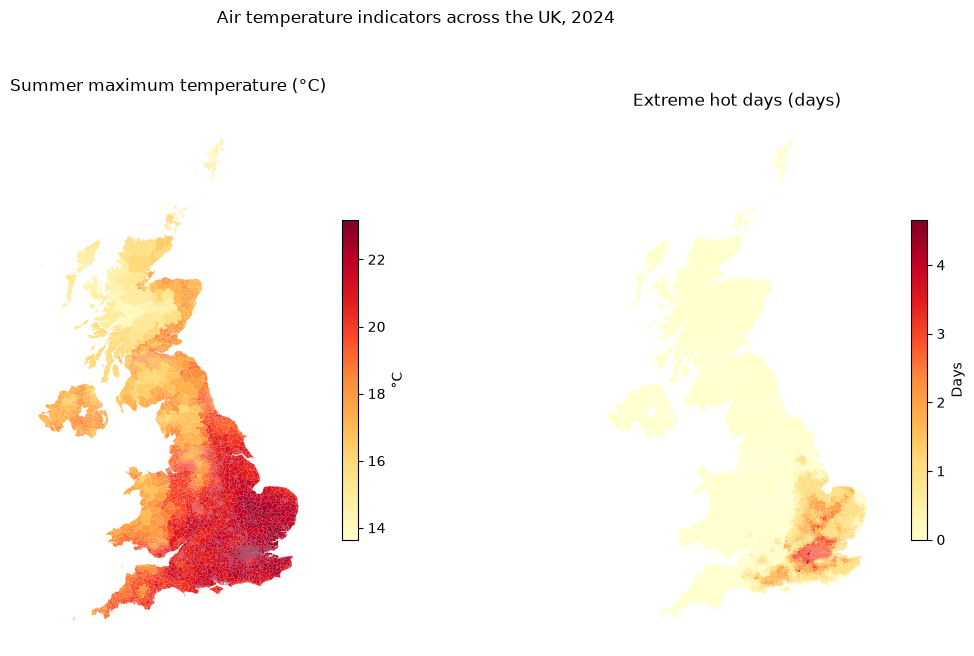

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, col, label, unit in zip(axes, indicators, labels, ["°C", "Days"]):
    msoa_temp.plot(column=col, cmap="YlOrRd", legend=True, ax=ax, linewidth=0,
                   legend_kwds={"shrink": 0.6, "label": unit},
                   missing_kwds={"color": "lightgrey", "label": "Missing"})
    ax.set_title(label)
    ax.set_axis_off()
fig.suptitle(f"Air temperature indicators across the UK, {year}")
plt.tight_layout(rect=(0, 0.05, 1, 0.95))
plt.show()

> **Note:** In 2024, higher summer maximum air temperatures are generally observed across southern and eastern England, while cooler conditions occur across much of Scotland and western upland areas. Higher values of the extreme hot days indicator are more geographically concentrated, particularly across parts of southern and eastern England.

## What Have We Learnt?

We have loaded the IMAGO air temperature product, inspected its variables and missing values, summarised two indicators and visualised their distributions and spatial patterns. The same workflow can be applied to other available years and indicators. The notes above describe the 2024 example; revisit them if you select another year.

## References and Further Training

- [IMAGO Data Catalogue](https://data.imago.ac.uk/) — product metadata and data access.
- [IMAGO Air Temperature — Basics](https://imago-sdruk.github.io/Imago_training/airtemp_1.html) — further training on air temperature analysis, including links with deprivation.
- [HadUK-Grid](https://www.metoffice.gov.uk/research/climate/maps-and-data/data/haduk-grid) — source data background.